# Tarea 1 — caracterización y reducción de ruido

**Ejecutar todas las celdas en orden con un kernel nuevo.** Este notebook integra 2.1–2.5 y regenera señales, metadatos, salidas, gráficas y métricas desde el código incluido. No necesita los resultados calculados previamente ni el repositorio original. Instalar `requirements.txt` y abrir desde la carpeta del paquete; en VS Code seleccionar el entorno con esas dependencias.

Las señales congeladas son de 8192 muestras a 8 kHz. La comparación principal utiliza 8174 muestras y compensa 18 muestras del FIR. Las mediciones del informe se conservan en `resultados/metricas.csv`; esta ejecución guarda resultados nuevos en `resultados/regenerados/`, porque tiempo y memoria dependen del equipo.

Responsables: integrante 1, fundamentos/generación; integrante 2, FIR; integrante 3, FFT/IFFT; integrante 4, comparación y propuesta. Autores: Saddy Guzman Rojas (2023088184), David García Cruz (2024115575), Válerin Calderón Bran (2020033313) y Luis Castro Montenegro (2013083843).

In [1]:
from pathlib import Path
import sys, os, json, csv, hashlib, subprocess
import numpy as np
import scipy
import matplotlib.pyplot as plt
from IPython.display import display, Image, HTML

candidatos = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "entrega/tarea1"]
RAIZ = next((p for p in candidatos if (p / "src/generar_senales.py").is_file() and (p / "metadatos/protocolo.json").is_file()), None)
if RAIZ is None:
    raise RuntimeError("Abrir este notebook desde la carpeta que contiene src/ y metadatos/.")
sys.path.insert(0, str(RAIZ / "src"))
SALIDA = RAIZ / "resultados/regenerados"
SALIDA.mkdir(parents=True, exist_ok=True)
print("Paquete:", RAIZ)
print("Python", sys.version.split()[0], "NumPy", np.__version__, "SciPy", scipy.__version__)

def mostrar(ruta):
    display(Image(filename=str(ruta), width=900))

def tabla(filas, campos):
    import html
    contenido = "<tr>" + "".join("<th>" + html.escape(c) + "</th>" for c in campos) + "</tr>"
    for fila in filas:
        contenido += "<tr>" + "".join("<td>" + html.escape(str(fila.get(c, ""))) + "</td>" for c in campos) + "</tr>"
    display(HTML("<table>" + contenido + "</table>"))

Paquete: <carpeta_del_paquete>
Python 3.12.14 NumPy 2.5.4 SciPy 1.18.1


## 2.1 — fundamentos y demostraciones
La serie de Fourier representa señales periódicas mediante líneas armónicas; la transformada de Fourier extiende la representación a señales aperiódicas. Para muestras finitas se usa la DFT: $X[k]=\sum_n x[n]e^{-j2\pi kn/N}$. La FFT es un algoritmo para esa misma transformación. Aquí se verifica la suma directa contra FFT, separación $\Delta f=f_s/N$, fuga rectangular/Hann, magnitud/fase y simetría conjugada. Modificar un solo miembro de un par produce una reconstrucción compleja.

2.1(a) DFT DIRECTA VS FFT
N = 32
Error máximo = 5.936975e-14

2.1(b) RESOLUCIÓN FRECUENCIAL
fs = 8000 Hz

   N       T [ms]      Δf [Hz]    memoria básica [KiB]
 256      32.000    31.250000               3.000
 512      64.000    15.625000               6.000
1024     128.000     7.812500              12.000
2048     256.000     3.906250              24.000



2.1(c) BIN EXACTO Y FUGA ESPECTRAL
fs = 8000.0 Hz
N = 1024
Δf = 7.812500 Hz
Tono exacto: k = 128, f = 1000.000000 Hz
Tono entre bins: k = 128.5, f = 1003.906250 Hz
Figura magnitud: <carpeta_del_paquete>/resultados/regenerados/fundamentos/figuras/2_1c_magnitud.png
Figura fase: <carpeta_del_paquete>/resultados/regenerados/fundamentos/figuras/2_1c_fase.png

2.1(d) SIMETRÍA CONJUGADA
Error máximo X[N-k] - conj(X[k]) = 1.421085e-14
Bin del tono de 1000 Hz = 128
Máx. parte imaginaria rompiendo simetría = 5.000000e-01
Máx. parte imaginaria preservando simetría = 1.110223e-16
Figura simetría: <carpeta_del_paquete>/resultados/regenerados/fundamentos/figuras/2_1d_simetria_conjugada.png
Figura IFFT: <carpeta_del_paquete>/resultados/regenerados/fundamentos/figuras/2_1d_ifft_simetria.png

RESULTADOS 2.1 GENERADOS
JSON: <carpeta_del_paquete>/resultados/regenerados/fundamentos/resultados_2_1.json


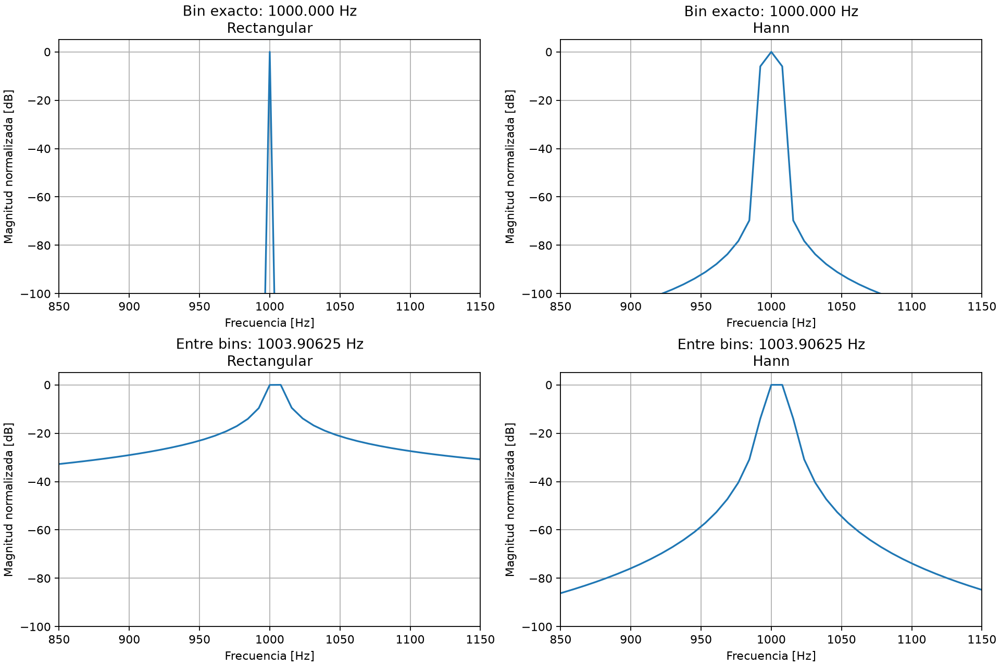

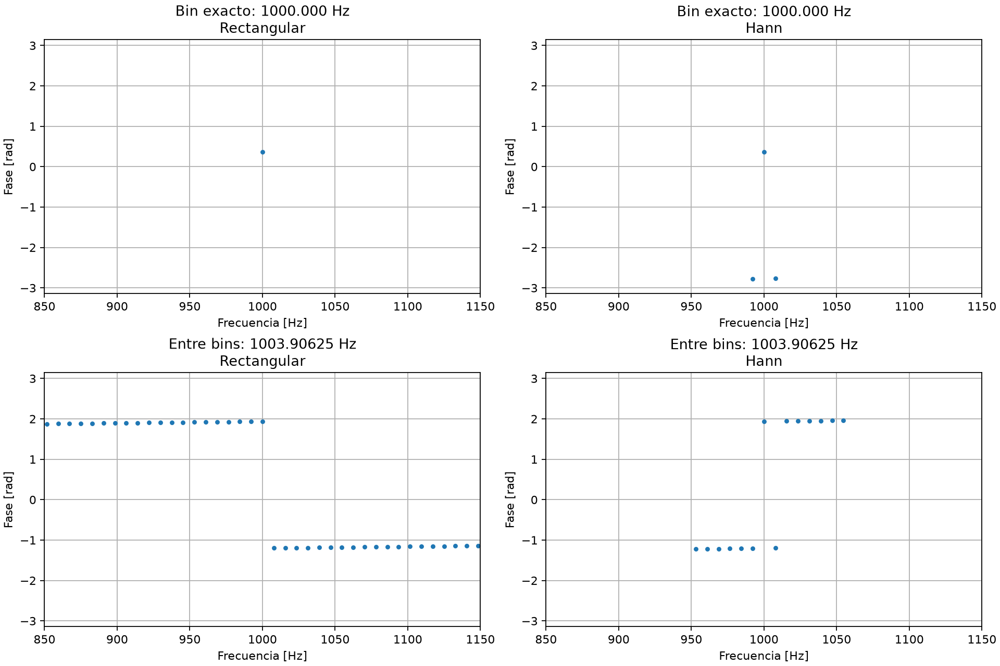

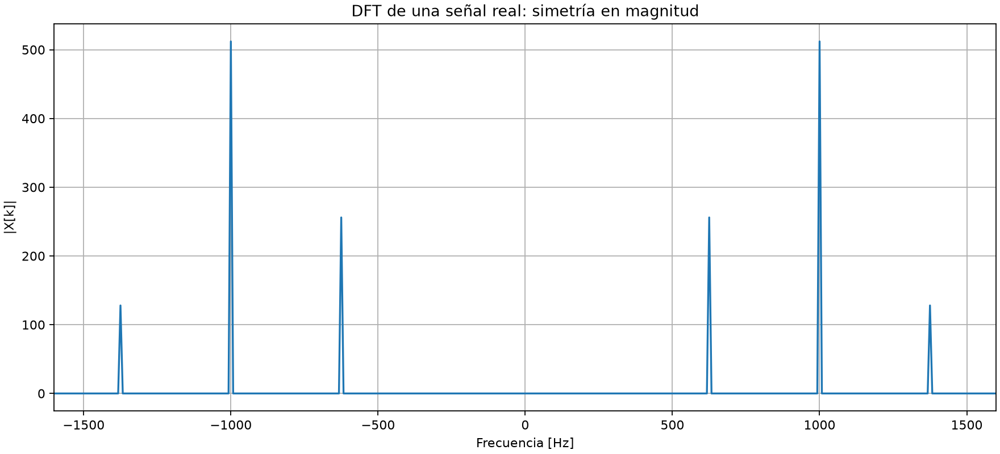

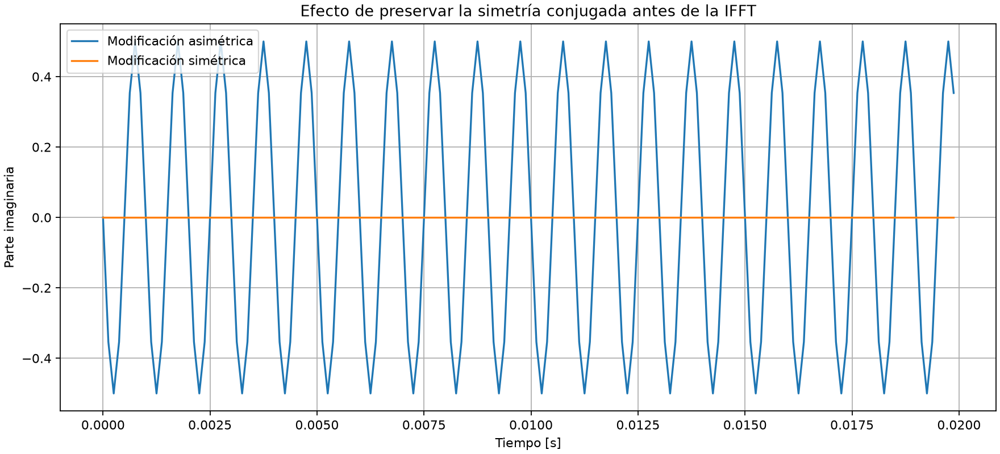

In [2]:
import analizar_2_1
analizar_2_1.main()
fundamentos = json.loads(analizar_2_1.RESULTADOS_JSON.read_text())
assert fundamentos["2_1a"]["error_max_dft_vs_fft"] < 1e-12
assert fundamentos["2_1d"]["max_imag_modificacion_simetrica"] < 1e-12
for nombre in ("2_1c_magnitud.png", "2_1c_fase.png", "2_1d_simetria_conjugada.png", "2_1d_ifft_simetria.png"):
    mostrar(analizar_2_1.FIGURAS / nombre)

## 2.2 — regeneración de los tres casos congelados
Se reutilizan las funciones y celdas oficiales de generación/caracterización, adaptando las rutas. Tonos útiles: 300, 700 y 1100 Hz; semillas 202601, 202602 y 202603. Casos: interferencia 2150 Hz a 0 dB, ruido blanco a 5 dB y banda 900–1300 Hz a 3 dB.

Se regeneran NPZ, WAV, metadatos agregados, gráficas y análisis de ruido. Las huellas de **los arreglos** se contrastan con las señales congeladas, independientemente del contenedor ZIP del NPZ. Solo después de verificarlas se actualiza la huella del archivo regenerado en el protocolo portable. La caracterización de ruido aislado es una prueba de referencia, no un clasificador demostrado de mezclas desconocidas.

caso_1 SNR objetivo: 0.0 SNR obtenida: 0.0
caso_2 SNR objetivo: 5.0 SNR obtenida: 5.0
caso_3 SNR objetivo: 3.0 SNR obtenida: 3.0

Generando gráficas del caso 1
Variables disponibles: ['limpia', 'ruido', 'contaminada', 'fs']



Generando gráficas del caso 2
Variables disponibles: ['limpia', 'ruido', 'contaminada', 'fs']



Generando gráficas del caso 3
Variables disponibles: ['limpia', 'ruido', 'contaminada', 'fs']



Todas las gráficas fueron generadas.

========== CASO 1 ==========
Tipo: Interferencia sinusoidal
Frecuencia detectada: 2150.39 Hz
Error absoluto: 0.39 Hz
Resultados guardados en: <carpeta_del_paquete>/resultados/regenerados/generacion/identificacion_ruido/caso_1/resultados.json

========== CASO 2 ==========
Tipo: Ruido blanco gaussiano
Distribución de energía por bandas:
0-500 Hz: 46806.76
500-1000 Hz: 46203.09
1000-1500 Hz: 44661.48
1500-2000 Hz: 48637.45
2000-2500 Hz: 47463.58
2500-3000 Hz: 47319.99
3000-3500 Hz: 43650.49
3500-4000 Hz: 44065.96
Coeficiente de variación: 0.0364
Resultados guardados en: <carpeta_del_paquete>/resultados/regenerados/generacion/identificacion_ruido/caso_2/resultados.json

========== CASO 3 ==========
Tipo: Ruido de banda limitada
Banda detectada: 870.12 - 1327.15 Hz
Resultados guardados en: <carpeta_del_paquete>/resultados/regenerados/generacion/identificacion_ruido/caso_3/resultados.json

Todos los resultados fueron guardados correctamente.


caso,semilla,tipo_ruido,snr_objetivo_dB,snr_obtenida_dB
caso_1,202601,tonal,0,1.2536257065192713e-14
caso_2,202602,blanco,5,5.000000000000009
caso_3,202603,banda,3,3.000000000000029


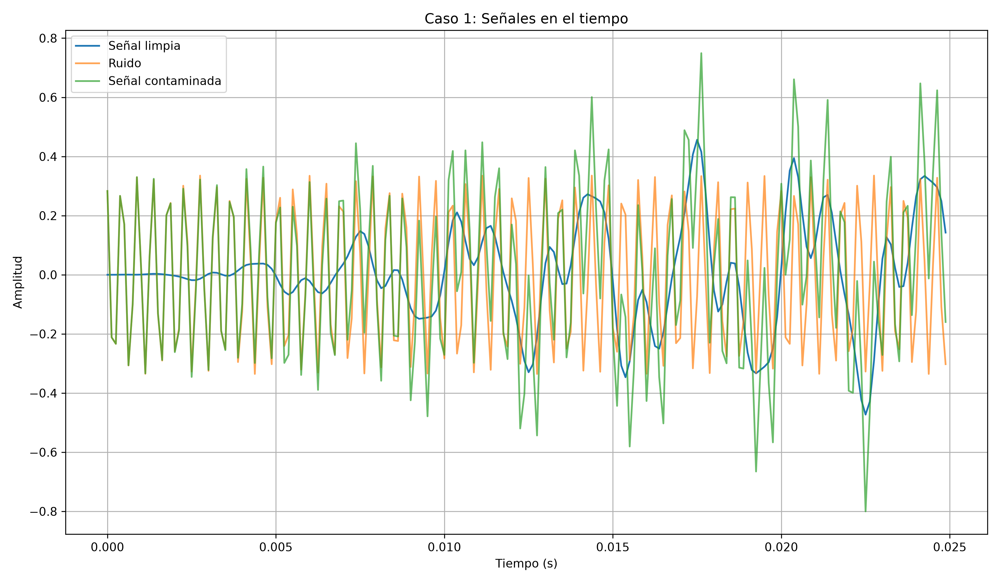

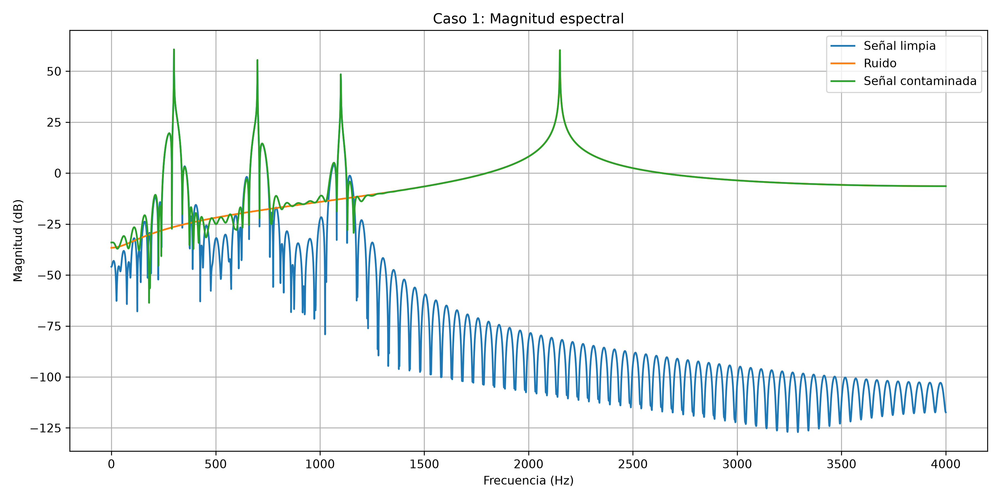

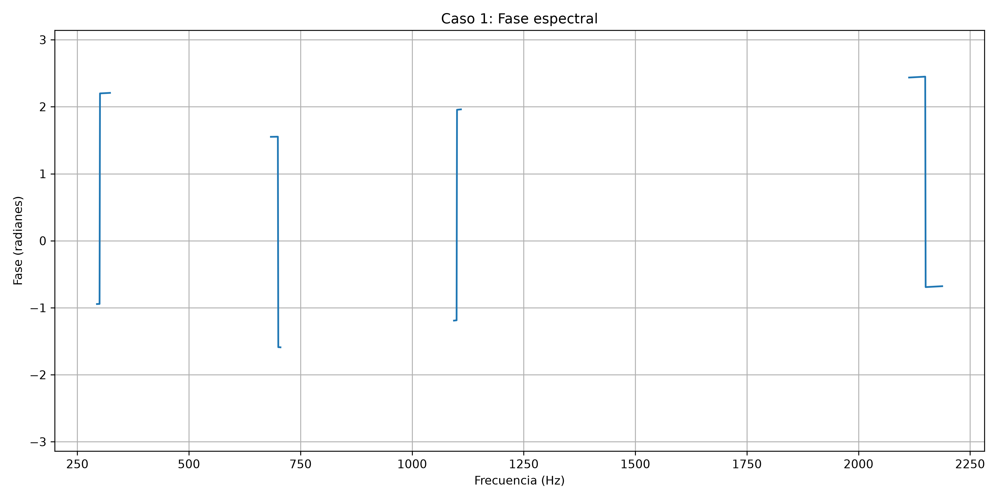

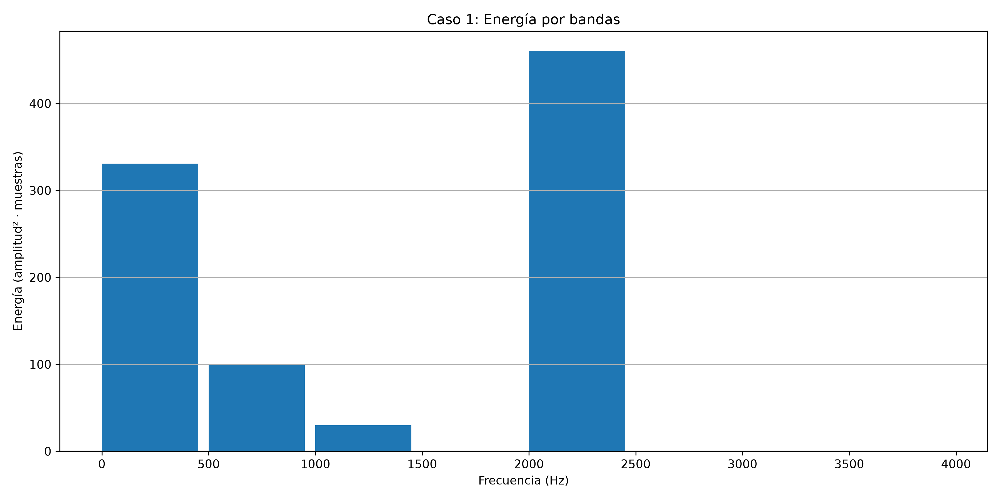

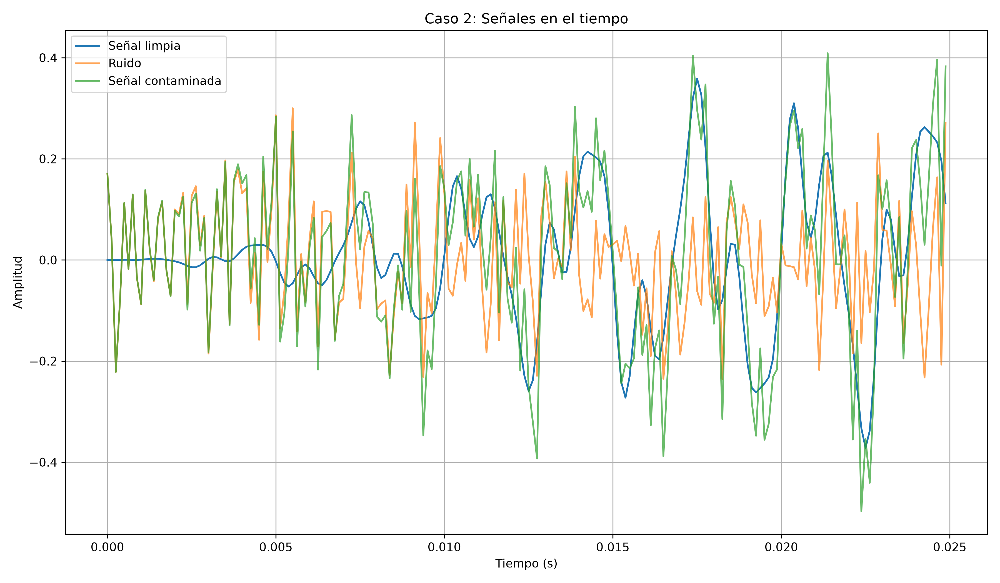

...

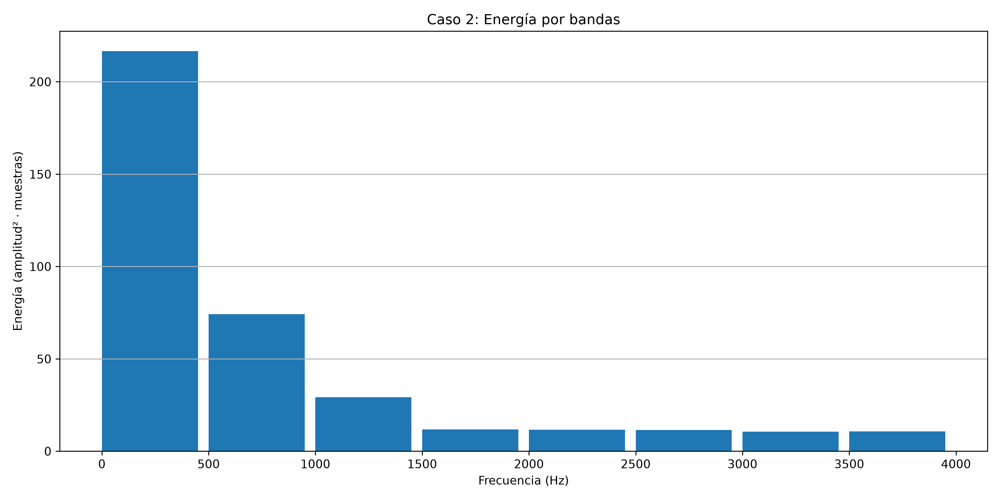

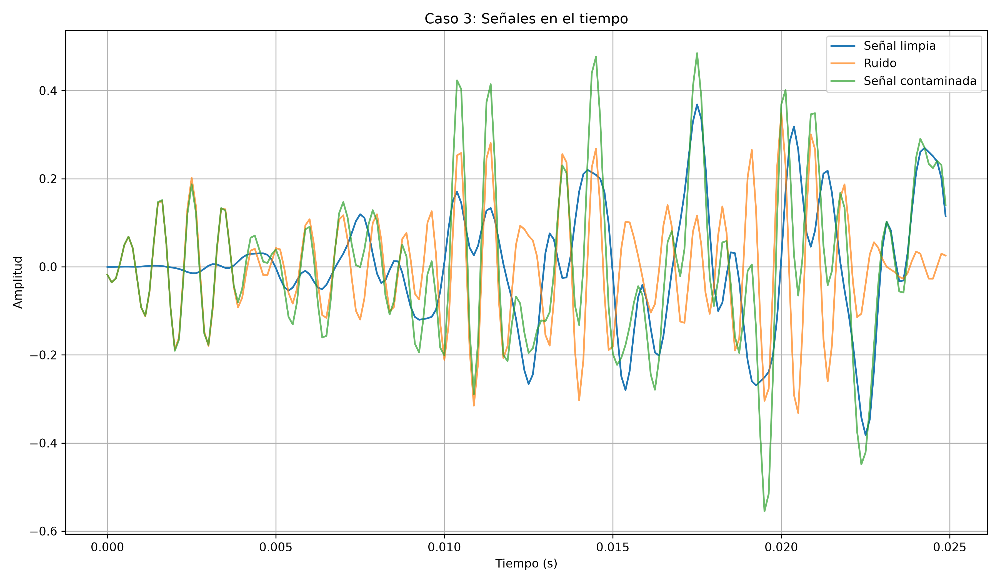

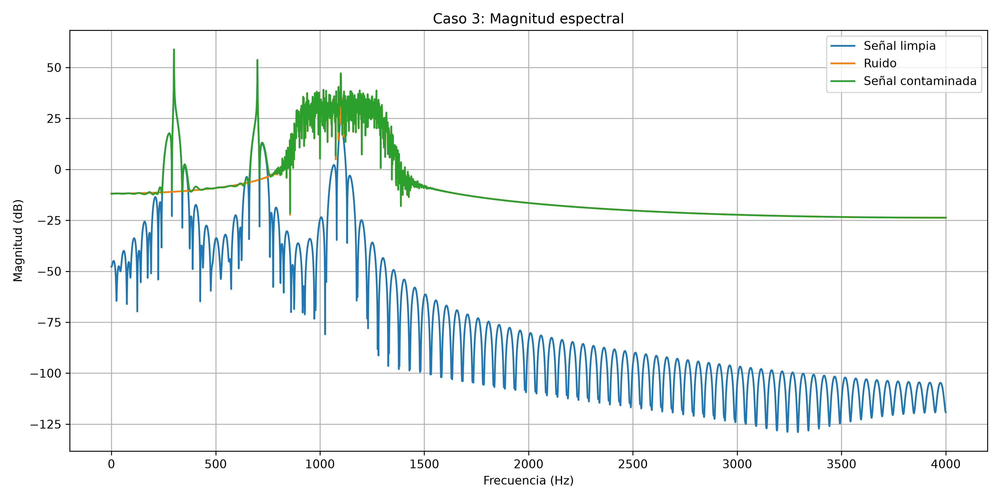

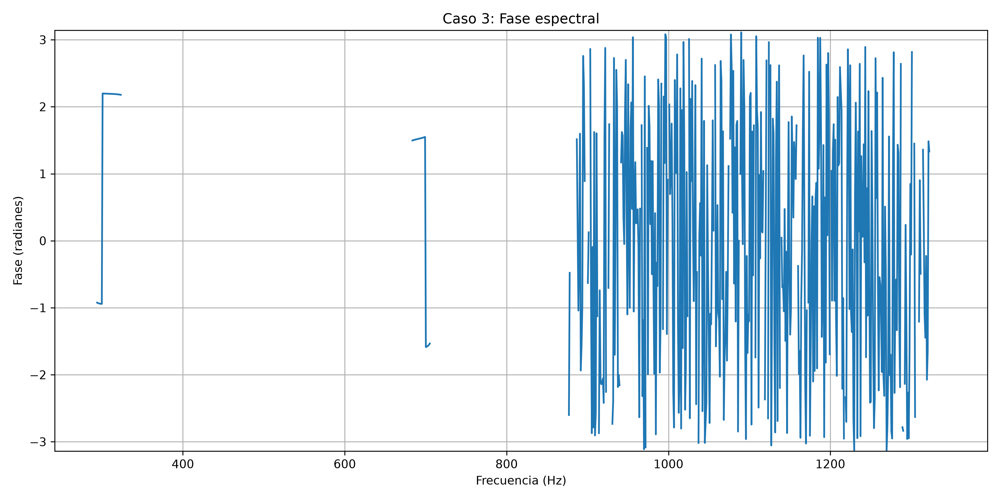

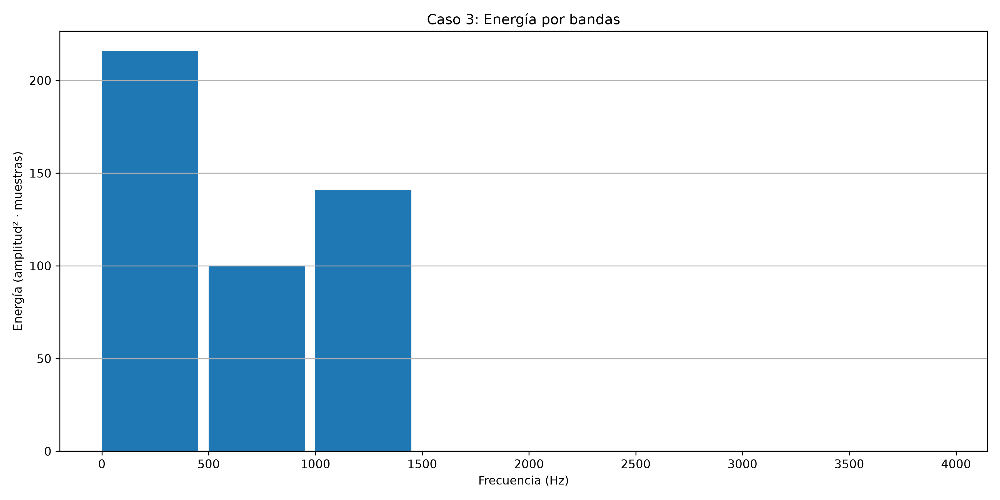

In [3]:
import generar_senales
generar_senales.regenerar()
protocolo_ruta = RAIZ / "metadatos/protocolo.json"
protocolo = json.loads(protocolo_ruta.read_text())
huellas = json.loads((RAIZ / "metadatos/huellas_muestras.json").read_text())
for caso in protocolo["casos"]:
    archivo = RAIZ / caso["archivo"]
    with np.load(archivo, allow_pickle=False) as datos:
        for nombre, esperado in huellas[str(caso["caso"])].items():
            if list(datos[nombre].shape) != esperado["shape"] or str(datos[nombre].dtype) != esperado["dtype"]:
                raise ValueError(f"Forma o precisión alterada: {caso['caso']} {nombre}")
            if hashlib.sha256(datos[nombre].tobytes()).hexdigest() != esperado["sha256"]:
                raise ValueError(f"Las muestras congeladas no se reprodujeron: {caso['caso']} {nombre}")
        np.testing.assert_allclose(datos["limpia"] + datos["ruido"], datos["contaminada"], atol=1e-14, rtol=0)
    caso["sha256"] = hashlib.sha256(archivo.read_bytes()).hexdigest()
protocolo_ruta.write_text(json.dumps(protocolo, ensure_ascii=False, indent=2) + "\n")
configuraciones = json.loads((RAIZ / "metadatos/configuraciones.json").read_text())
tabla([dict(caso=k, **v) for k,v in configuraciones.items()], ["caso", "semilla", "tipo_ruido", "snr_objetivo_dB", "snr_obtenida_dB"])
for caso in (1,2,3):
    for nombre in ("temporal", "magnitud", "fase", "energia"):
        mostrar(SALIDA / f"generacion/figuras/caso_{caso}/{nombre}.png")

## 2.3 — filtro temporal definitivo
FIR Kaiser pasa bajas, orden 36 y 37 coeficientes: paso hasta 1200 Hz, rechazo desde 1800 Hz, corte 1500 Hz, pérdida permitida 1 dB y atenuación mínima 40 dB. Se seleccionó frente al Butterworth por fase lineal y estado sin realimentación.

$y[n]=\sum_{k=0}^{36}b[k]x[n-k]$ y $H(z)=\sum b[k]z^{-k}$. Tiene 36 polos en el origen, ROC causal $|z|>0$, estabilidad y retardo de 18 muestras. La ecuación manual se verifica contra SciPy sobre cada caso. Los bloques conservan estado; no se reinicia entre llamadas.

Caso 1 error manual/SciPy: 2.7755575615628914e-16
Caso 2 error manual/SciPy: 3.3306690738754696e-16


Caso 3 error manual/SciPy: 3.3306690738754696e-16


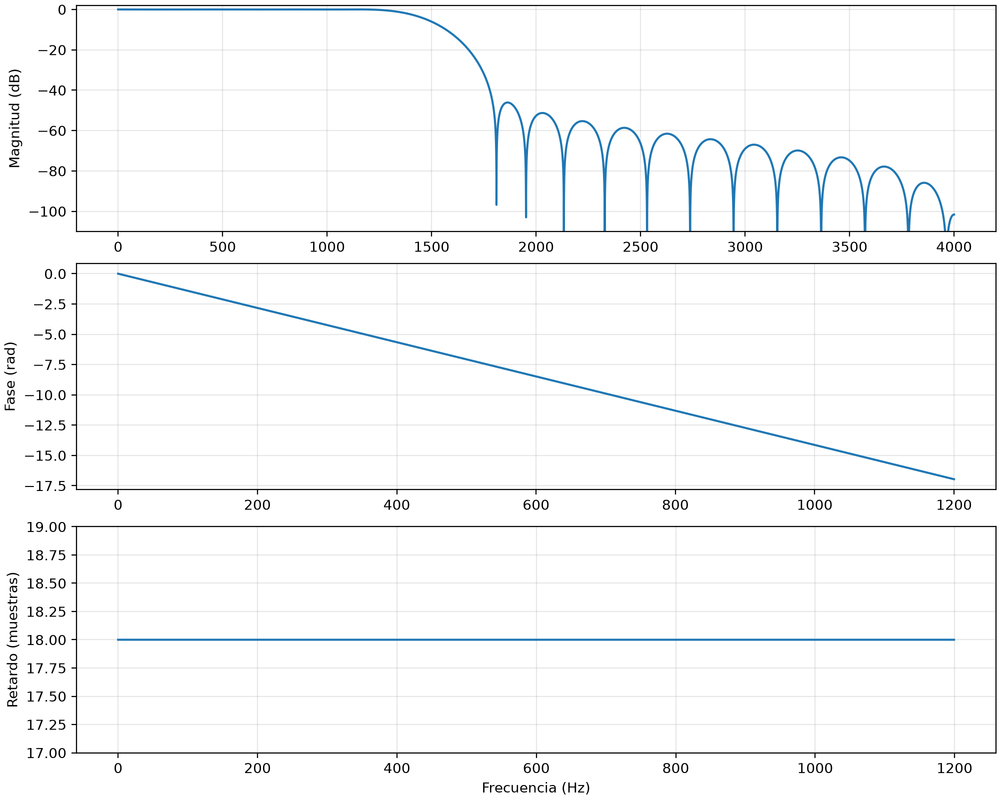

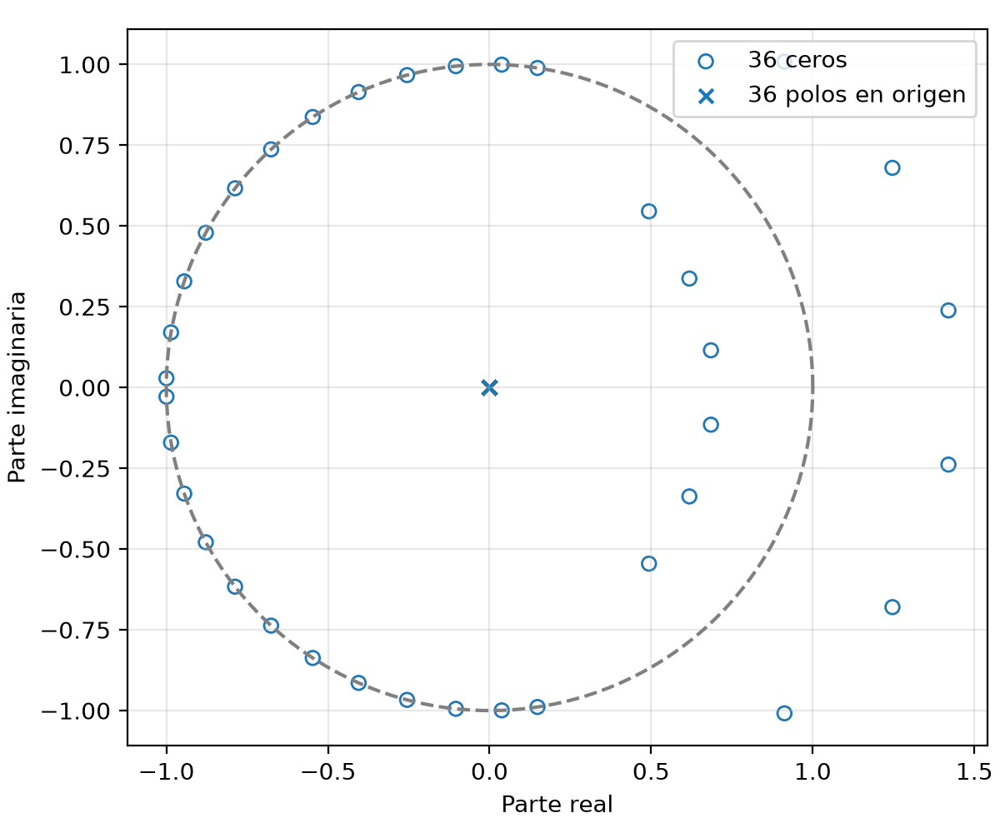

In [4]:
from filtros_temporales import disenar_fir_kaiser, aplicar_filtro_manual_bloque, obtener_polos_ceros
from scipy import signal
b, a, orden = disenar_fir_kaiser(8000, 1200, 1800)
assert orden == 36 and len(b) == 37
for caso in (1,2,3):
    with np.load(RAIZ / f"pruebas/caso_{caso}/muestras_exactas.npz") as datos:
        x = datos["contaminada"]
    estado=None; partes=[]
    for inicio in range(0,len(x),1024):
        y,estado=aplicar_filtro_manual_bloque(x[inicio:inicio+1024],b,a,estado)
        partes.append(y)
    error=float(np.max(np.abs(np.concatenate(partes)-signal.lfilter(b,a,x))))
    assert error < 1e-12
    print("Caso",caso,"error manual/SciPy:",error)
(SALIDA / "temporal").mkdir(exist_ok=True)
(SALIDA / "temporal/coeficientes.json").write_text(json.dumps({"b":b.tolist(),"a":a.tolist(),"retardo_muestras":18},indent=2))
f,h=signal.freqz(b,a,worN=16384,fs=8000)
fg,g=signal.group_delay((b,a),w=4096,fs=8000)
fig,ax=plt.subplots(3,1,figsize=(10,8),layout="constrained")
ax[0].plot(f,20*np.log10(np.maximum(np.abs(h),1e-12)));ax[0].set(ylabel="Magnitud (dB)",ylim=(-110,2))
mask=f<=1200
ax[1].plot(f[mask],np.unwrap(np.angle(h))[mask]);ax[1].set(ylabel="Fase (rad)")
ax[2].plot(fg[fg<=1200],g[fg<=1200]);ax[2].set(ylabel="Retardo (muestras)",xlabel="Frecuencia (Hz)",ylim=(17,19))
for eje in ax:eje.grid(alpha=.3)
fig.savefig(SALIDA / "temporal/respuesta.png",dpi=200);plt.close(fig)
ceros,polos=obtener_polos_ceros(b,a)
fig,ax=plt.subplots(figsize=(6,5),layout="constrained");ang=np.linspace(0,2*np.pi,500)
ax.plot(np.cos(ang),np.sin(ang),"--",color="gray")
ax.scatter(ceros.real,ceros.imag,facecolors="none",edgecolors="C0",label="36 ceros")
ax.scatter(polos.real,polos.imag,marker="x",label="36 polos en origen")
ax.set(xlabel="Parte real",ylabel="Parte imaginaria",aspect="equal");ax.grid(alpha=.3);ax.legend()
fig.savefig(SALIDA / "temporal/polos_ceros.png",dpi=200);plt.close(fig)
mostrar(SALIDA / "temporal/respuesta.png");mostrar(SALIDA / "temporal/polos_ceros.png")

## 2.4 — adaptación FFT/IFFT y compromiso de sustracción
La cadena usa raíz de Hann periódica, FFT real, ganancias adaptadas desde la mezcla, IFFT y solapamiento del 50 %. `picos` rechaza máximos externos a la banda útil sin recibir su frecuencia exacta; `resta` aplica sustracción con protección de tonos persistentes. La evaluación actual usa mediana temporal de la captura completa: es fuera de línea.

Se ejecutan los tres métodos por caso y la ablación sin protección tonal. Estas métricas usan 8192 muestras y se muestran aparte de la comparación común de 8174.

In [5]:
import importlib.util
ruta = RAIZ / "pruebas/filtrado_espectral/evaluar_casos.py"
spec=importlib.util.spec_from_file_location("evaluar_espectral_notebook",ruta)
espectral=importlib.util.module_from_spec(spec);spec.loader.exec_module(espectral)
espectral.main()
compromiso=espectral.evaluar_compromiso()
tabla(compromiso,["alpha","atenuacion_fuera_tonos_db","snr_salida_db","ganancia_1100_Hz_db"])
assert next(v for v in compromiso if v["alpha"]==8)["snr_salida_db"] < next(v for v in compromiso if v["alpha"]==2)["snr_salida_db"]

Caso 1 (tonal): picos; SNR 0.00 -> 30.31 dB; MSE 0.000052; tono 1100 Hz -0.00 dB
Caso 2 (blanco): resta; SNR 5.00 -> 20.73 dB; MSE 0.000294; tono 1100 Hz -0.09 dB
Caso 3 (banda): resta; SNR 3.00 -> 14.67 dB; MSE 0.001252; tono 1100 Hz +1.03 dB
Resultados: <carpeta_del_paquete>/resultados/regenerados/espectral


alpha,atenuacion_fuera_tonos_db,snr_salida_db,ganancia_1100_Hz_db
0,-9.643274665532873e-16,5.000000000000009,-0.02351031644522609
0.5,3.63329882296265,8.666958449943476,-0.6377311084895414
1,8.489076462300245,13.084296302817098,-1.2952997769967944
2,20.61576715767604,16.93831210974234,-2.706811962146787
3,25.851632870448253,14.736837447025515,-4.277312241403864
4,25.950638107923247,12.704733492168899,-6.03763089527673
8,25.98383261533329,7.643463756088225,-15.581855267603395


## 2.5 — comparación homogénea y medición de recursos
Se conserva la referencia `s[0:8174]`. La salida FIR usa `[18:8192]` y la espectral `[0:8174]`. MSE y SNR penalizan ruido residual y distorsión; energía útil se obtiene aplicando a `s` el operador con ganancias fijadas desde `x`. No se reestiman ganancias desde la limpia ni se confunde energía total con energía útil.

Se miden 30 repeticiones tras tres calentamientos. El tiempo por 1024 muestras se amortiza sobre la captura; no es latencia causal. El pico trazado puede omitir asignaciones nativas. El FIR manual Python y la FFT vectorizada no predicen la relación de tiempos en ESP32. Los valores nuevos se guardan aparte del benchmark del informe.

Caso 1: calidad, separación de fuentes y recursos…


Caso 2: calidad, separación de fuentes y recursos…


Caso 3: calidad, separación de fuentes y recursos…


Caso 1 entrada: SNR 0.010 dB; energía útil 100.000 %
Caso 1 temporal_fir: SNR 51.911 dB; energía útil 99.643 %
Caso 1 espectral: SNR 32.166 dB; energía útil 100.000 %
Caso 2 entrada: SNR 5.009 dB; energía útil 100.000 %
Caso 2 temporal_fir: SNR 9.524 dB; energía útil 99.643 %
Caso 2 espectral: SNR 20.813 dB; energía útil 99.016 %
Caso 3 entrada: SNR 3.010 dB; energía útil 100.000 %
Caso 3 temporal_fir: SNR 3.071 dB; energía útil 99.643 %
Caso 3 espectral: SNR 14.677 dB; energía útil 99.764 %
Resultados: <carpeta_del_paquete>/resultados/regenerados


Verificados nueve registros; generadas 6 figuras PNG/SVG y cuatro tablas.
Resultados: <carpeta_del_paquete>/resultados/regenerados


caso,metodo,mse,snr_salida_db,delta_snr_db,energia_util_conservada_pct,atenuacion_ruido_total_db,tiempo_equivalente_1024_mediana_ms
1,entrada,0.0562239984765872,0.009618276728530054,0.0,100.0,0.0,0.0
1,temporal_fir,3.6289063986133926e-07,51.91107789253353,51.901459615804995,99.64277926199995,55.555877296454156,5.897872250000001
1,espectral,3.4221151190182827e-05,32.16588940722047,32.15627113049194,99.99998803673404,32.15600973674451,0.1228946875
2,entrada,0.010992304299116164,5.009156483185794,0.0,100.0,0.0,0.0
2,temporal_fir,0.003887311098055498,9.523550925174181,4.514394441988387,99.64277926199996,4.5141009648437285,6.9649041875
2,espectral,0.00028886605840766513,20.813078752461003,15.803922269275208,99.01584945548086,17.22222544557063,0.30375850000000004
3,entrada,0.01838450077030246,3.00974696257391,0.0,100.0,0.0,0.0
3,temporal_fir,0.018128009915070065,3.070764073336238,0.06101711076232785,99.64277926199998,0.06118771358537548,7.6286608125
3,espectral,0.0012523431295509049,14.67703199845742,11.66728503588351,99.76426313480162,11.765610261977304,0.2034544375


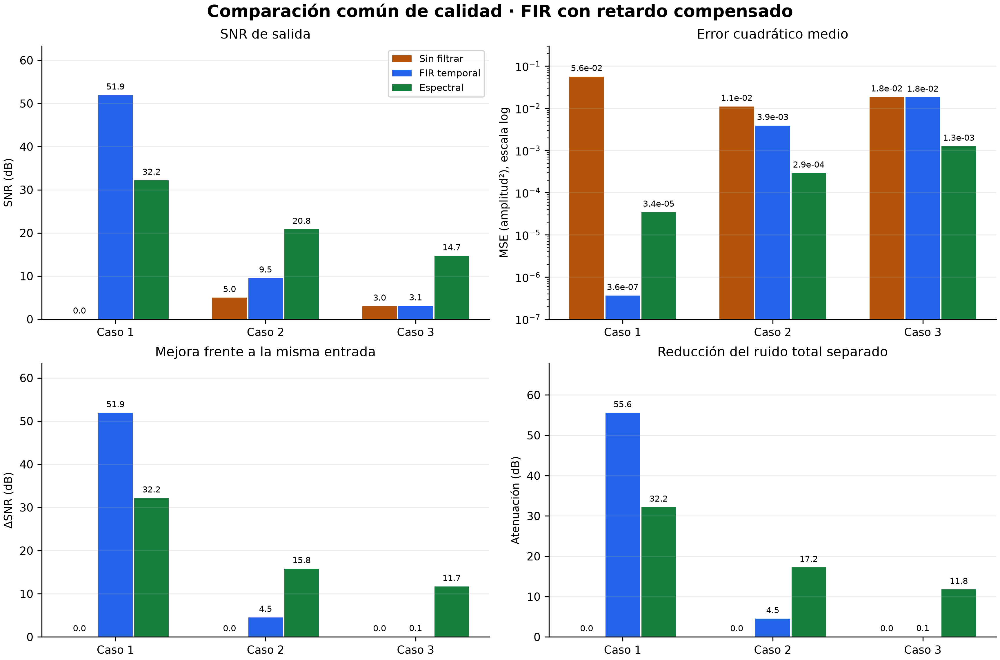

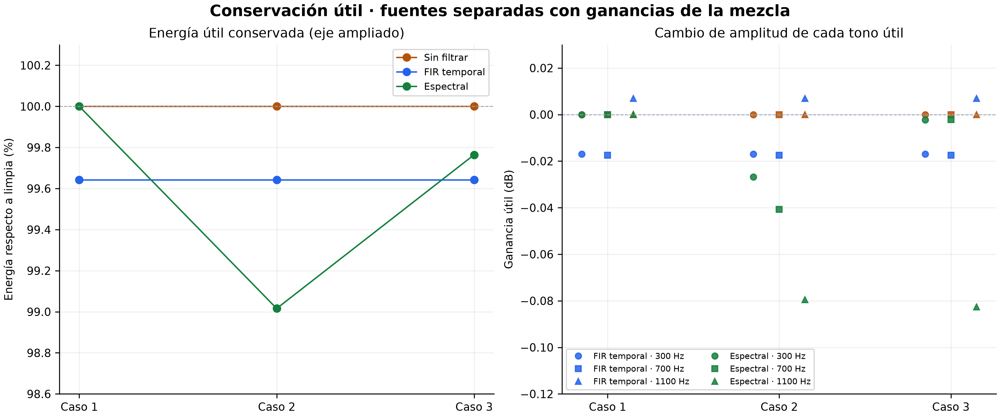

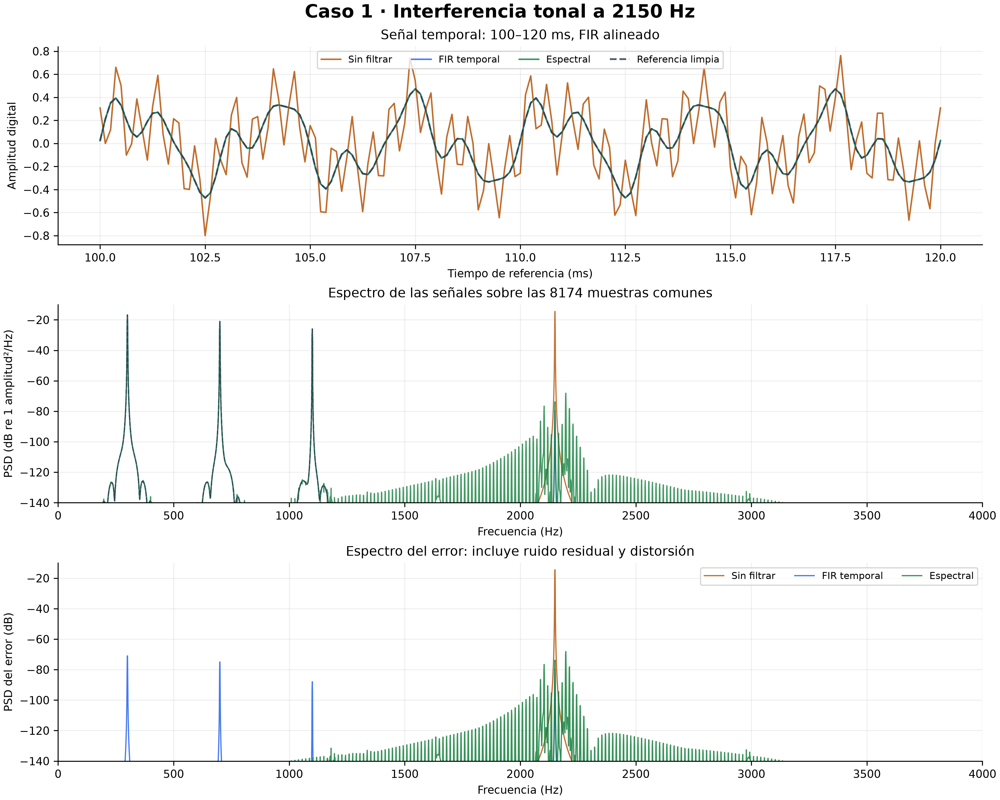

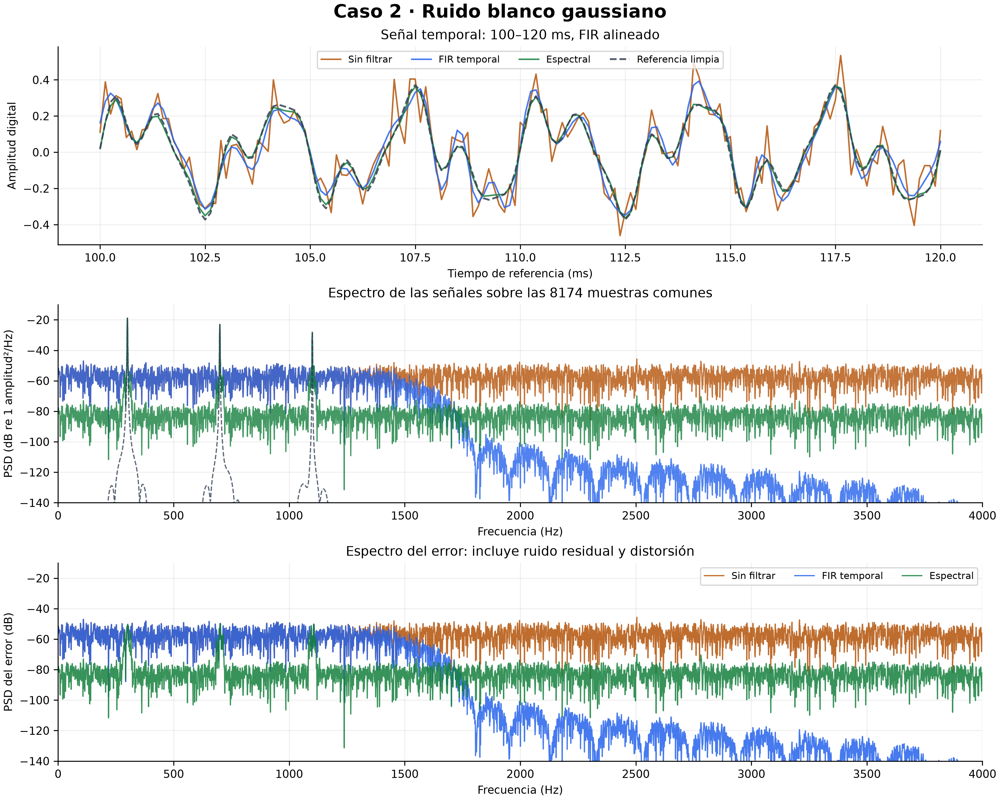

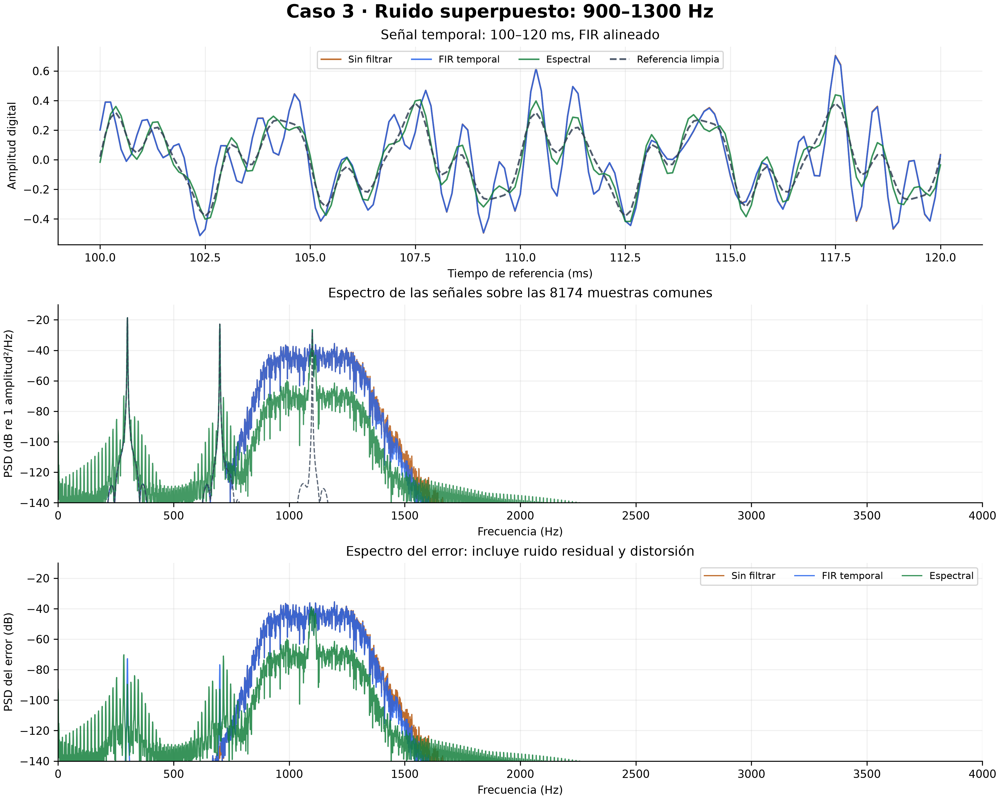

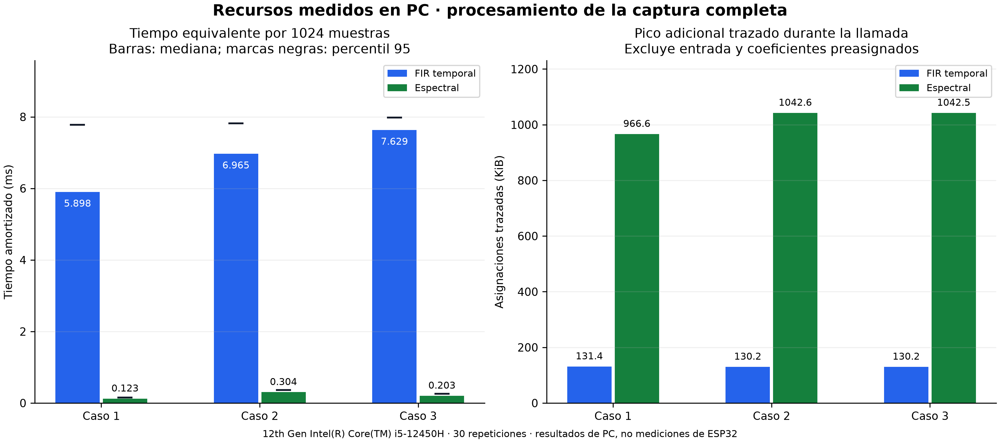

In [6]:
import evaluar_comparacion, graficar_comparacion
for modulo in (generar_senales, evaluar_comparacion, graficar_comparacion):
    assert Path(modulo.__file__).resolve().is_relative_to(RAIZ)
detalle=evaluar_comparacion.ejecutar(protocolo_ruta,SALIDA,benchmark=True)
graficar_comparacion.generar(SALIDA)
tabla(detalle["filas"],["caso","metodo","mse","snr_salida_db","delta_snr_db","energia_util_conservada_pct","atenuacion_ruido_total_db","tiempo_equivalente_1024_mediana_ms"])
for nombre in ("resumen_calidad","energia_y_tonos","caso_1_comparacion","caso_2_comparacion","caso_3_comparacion","recursos_pc"):
    mostrar(SALIDA / f"figuras/{nombre}.png")

## Validación de la integración
Las pruebas incluyen resultados conocidos de métricas, rechazo de datos alterados, equivalencia FIR/SciPy, identidad y simetría espectral, adaptación a interferencia desplazada y conservación de fuentes. Los ocho scripts temporales tienen aserciones en su programa principal: se ejecutan individualmente, no mediante un descubrimiento que omitiría sus comprobaciones.

In [7]:
comandos=[]
for archivo in sorted((RAIZ / "pruebas/filtros_temporales").glob("test_*.py")):
    comandos.append([sys.executable,str(archivo)])
for carpeta in ("filtrado_espectral","comparacion"):
    comandos.append([sys.executable,"-m","unittest","discover","-s",str(RAIZ / "pruebas" / carpeta),"-p","test_*.py","-v"])
registro=[]
for comando in comandos:
    proceso=subprocess.run(comando,cwd=RAIZ,capture_output=True,text=True,timeout=180)
    nombre=Path(comando[1]).stem if len(comando)==2 else "pruebas_"+Path(comando[5]).name
    (SALIDA / f"{nombre}.log").write_text(proceso.stdout+proceso.stderr)
    if proceso.returncode:
        raise RuntimeError(proceso.stdout+proceso.stderr)
    registro.append({"comando":comando[1:],"resultado":"correcto"})
print("Correctos:",len(registro),"grupos de pruebas (8 scripts FIR, 4 pruebas espectrales y 9 de comparación).")
(SALIDA / "pruebas_ejecutadas.json").write_text(json.dumps(registro,indent=2))
if (RAIZ / "resultados/metricas.csv").is_file():
    with (RAIZ / "resultados/metricas.csv").open() as f:referencia=list(csv.DictReader(f))
    campos_calidad=["mse","snr_salida_db","delta_snr_db","energia_util_conservada_pct","energia_total_salida_pct","atenuacion_ruido_total_db"]
    for original,nuevo in zip(referencia,detalle["filas"]):
        assert int(original["caso"])==nuevo["caso"] and original["metodo"]==nuevo["metodo"]
        for campo in campos_calidad:
            np.testing.assert_allclose(float(original[campo]),nuevo[campo],atol=1e-10,rtol=1e-10)
    print("Calidad reproducida respecto al informe; los tiempos nuevos se conservan separados.")
else:
    esperadas={1:51.91107789253353,2:20.813078752461003,3:14.67703199845742}
    for caso, esperado in esperadas.items():
        metodo="temporal_fir" if caso==1 else "espectral"
        fila=next(f for f in detalle["filas"] if f["caso"]==caso and f["metodo"]==metodo)
        np.testing.assert_allclose(fila["snr_salida_db"],esperado,atol=1e-10,rtol=1e-10)
    print("Calidad verificada sin resultados precalculados disponibles.")

Correctos: 10 grupos de pruebas (8 scripts FIR, 4 pruebas espectrales y 9 de comparación).
Calidad verificada sin resultados precalculados disponibles.


## Decisión y traslado a tres ESP32
Los resultados favorecen FIR para el caso tonal separado (SNR 51.911 dB) y FFT/IFFT para blanco y banda superpuesta (20.813 y 14.677 dB). Ninguno recupera perfectamente información cuando ruido y señal comparten frecuencia.

La propuesta usa tres ESP32 clásicos: N1 adquisición/FFT de diagnóstico, N2 FIR con salida física y N3 FFT/IFFT, salida y evaluación. Se proponen 8 kHz, FFT 1024, salto 512 y `float32`; piso causal de ocho tramas y DC causal. N3 usa la referencia únicamente en ensayos de evaluación. UART independientes a 921600 baudios transportan lotes de 512 muestras: hasta 2094 B para un canal, 4150 B para `(x,s)`, más 102 B de diagnóstico. El enlace crítico requiere 664375 baudios sin control, y el retardo modelado de reproducción es 256 ms. Las memorias completas presupuestadas son 71.16, 45.56 y 134.16 KiB para N1–N3.

ESP-DSP 1.8.2 (Apache 2.0) se propone para FFT/FIR; KISS FFT 131.1.0 (BSD de tres cláusulas) es alternativa. Estos son presupuestos y fuentes revisadas, no firmware probado. El informe y `documentacion/` contienen fundamentos, licencias, bibliografía, protocolo y límites.

**Uso de IA:** se suministraron enunciados, plan, aportes, libros, código y datos para apoyar integración, pruebas y documentación. Este notebook verifica ejecución y calidad contra las fuentes congeladas. La portada contiene los nombres y carnés. El README identifica el repositorio y la versión de entrega mediante la etiqueta `tarea1_prototipo`.